# 03 – Dự báo nhu cầu: baseline và đánh giá

**Mục tiêu.** Thiết lập mức sai số tham chiếu mà các mô hình học máy phải vượt, bằng các baseline lịch sử được đánh giá trong cùng giao thức rolling one-day-ahead.

**Giao thức.**
- Cửa sổ thực nghiệm chính 27/6–2/10: train 27/6–23/8, validation 24/8–12/9, test 13/9–2/10. Toàn kỳ 12/5–28/10 được chạy làm kịch bản độ nhạy.
- Tại ngày $t$ chỉ dùng nhu cầu đã quan sát đến $t-1$; các baseline rolling được cập nhật hằng ngày. Trung bình lịch sử và trung bình cùng thứ được fit một lần trên train.
- Mô hình được chọn bằng WAPE trên validation, không dùng test để chọn.
- MAE và RMSE tính trên từng ô (chuỗi, ngày). WAPE bằng tổng sai số tuyệt đối chia tổng nhu cầu. Báo cáo ở mức chuỗi và sau khi cộng dự báo theo `region_id`.
- Mọi baseline được chấm trên đúng cùng tập ô.

In [1]:
import sys, json
from pathlib import Path
root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(root))  # repository root, so that `src` is importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from src import config

from src import train_forecast, evaluate_forecast
from src.visualization import saveFigure, plotActualVsPredicted

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
dateCol = config.DEMAND_DATE_COLUMN

train_forecast.main()     # features and baseline predictions of both scenarios
evaluate_forecast.main()  # metrics and protocol
metrics = pd.read_csv(config.BASELINE_METRICS_FILE)
predictions = pd.read_csv(config.BASELINE_PREDICTIONS_FILE, parse_dates=[dateCol])
protocol = {p["scenario"]: p for p in json.loads(config.BASELINE_PROTOCOL_FILE.read_text(encoding="utf-8"))}

baseline predictions: 21,648 rows
             model    mae   rmse   wape
    rolling_mean_7 1.3115 3.2093 0.2273
   rolling_mean_14 1.3767 3.3355 0.2386
historical_weekday 1.4394 3.5779 0.2494
   historical_mean 1.4528 3.5936 0.2518
           naive_1 1.6317 4.1967 0.2828
        seasonal_7 1.7683 4.3139 0.3064


## 1. Giao thức đã chạy

In [2]:
rows = []
for name, p in protocol.items():
    rows.append({"scenario": name, "train": " .. ".join(p["splits"]["train"]), "validation": " .. ".join(p["splits"]["validation"]),
                 "test": " .. ".join(p["splits"]["test"]), "eligible train days": p["ready_train_days"],
                 "scored validation days": p["scored_days"]["validation"], "scored test days": p["scored_days"]["test"],
                 "selected on validation": p["selected_on_validation"]})
display(pd.DataFrame(rows).set_index("scenario").T)
print("evaluation days excluded in the full-period scenario:", protocol["sensitivity_full_period"]["excluded_eval_days"])

scenario,primary_stable_period,sensitivity_full_period
train,2022-06-27 .. 2022-08-23,2022-05-12 .. 2022-08-21
validation,2022-08-24 .. 2022-09-12,2022-08-22 .. 2022-09-24
test,2022-09-13 .. 2022-10-02,2022-09-25 .. 2022-10-28
eligible train days,44,72
scored validation days,20,34
scored test days,20,14
selected on validation,rolling_mean_7,rolling_mean_7


evaluation days excluded in the full-period scenario: ['2022-10-09', '2022-10-10', '2022-10-11', '2022-10-12', '2022-10-13', '2022-10-14', '2022-10-15', '2022-10-16', '2022-10-17', '2022-10-18', '2022-10-19', '2022-10-20', '2022-10-21', '2022-10-22', '2022-10-23', '2022-10-24', '2022-10-25', '2022-10-26', '2022-10-27', '2022-10-28']


## 2. So sánh baseline – cửa sổ thực nghiệm chính

--- validation, series level


,mae,rmse,wape,rows,actual_orders
model,,,,,
rolling_mean_7,1.3716,3.4199,0.2122,820,5300.0
rolling_mean_14,1.4201,3.5958,0.2197,820,5300.0
historical_mean,1.5911,4.0467,0.2462,820,5300.0
historical_weekday,1.6342,4.0962,0.2528,820,5300.0
seasonal_7,1.7951,4.4057,0.2777,820,5300.0
naive_1,1.8476,4.7405,0.2858,820,5300.0


--- test, series level


,mae,rmse,wape,rows,actual_orders
model,,,,,
rolling_mean_7,1.3115,3.2093,0.2273,820,4732.0
rolling_mean_14,1.3767,3.3355,0.2386,820,4732.0
historical_weekday,1.4394,3.5779,0.2494,820,4732.0
historical_mean,1.4528,3.5936,0.2518,820,4732.0
naive_1,1.6317,4.1967,0.2828,820,4732.0
seasonal_7,1.7683,4.3139,0.3064,820,4732.0


--- test, after summing predictions by region


,mae,rmse,wape,rows,actual_orders
model,,,,,
rolling_mean_7,8.8357,12.2432,0.1494,80,4732.0
rolling_mean_14,9.5759,12.7445,0.1619,80,4732.0
historical_weekday,9.9858,13.6526,0.1688,80,4732.0
historical_mean,10.2142,14.0008,0.1727,80,4732.0
naive_1,10.8250,15.5161,0.1830,80,4732.0
seasonal_7,12.2000,16.1168,0.2063,80,4732.0


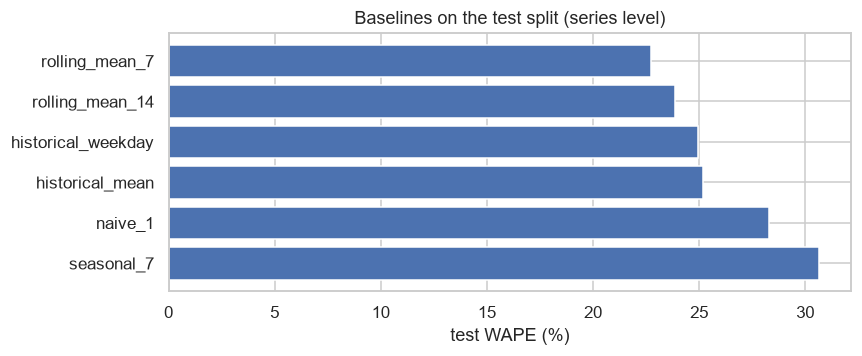

In [3]:
primary = metrics[metrics.scenario == "primary_stable_period"]
for split in ("validation", "test"):
    print(f"--- {split}, series level")
    display(primary[(primary.split == split) & (primary.level == "series")][["model", "mae", "rmse", "wape", "rows", "actual_orders"]].sort_values("wape").round(4).set_index("model"))
print("--- test, after summing predictions by region")
display(primary[(primary.split == "test") & (primary.level == "region")][["model", "mae", "rmse", "wape", "rows", "actual_orders"]].sort_values("wape").round(4).set_index("model"))

test = primary[(primary.split == "test") & (primary.level == "series")].sort_values("wape")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(test["model"], test["wape"] * 100); ax.invert_yaxis(); ax.set_xlabel("test WAPE (%)"); ax.set_title("Baselines on the test split (series level)")
saveFigure("baseline_test_wape")

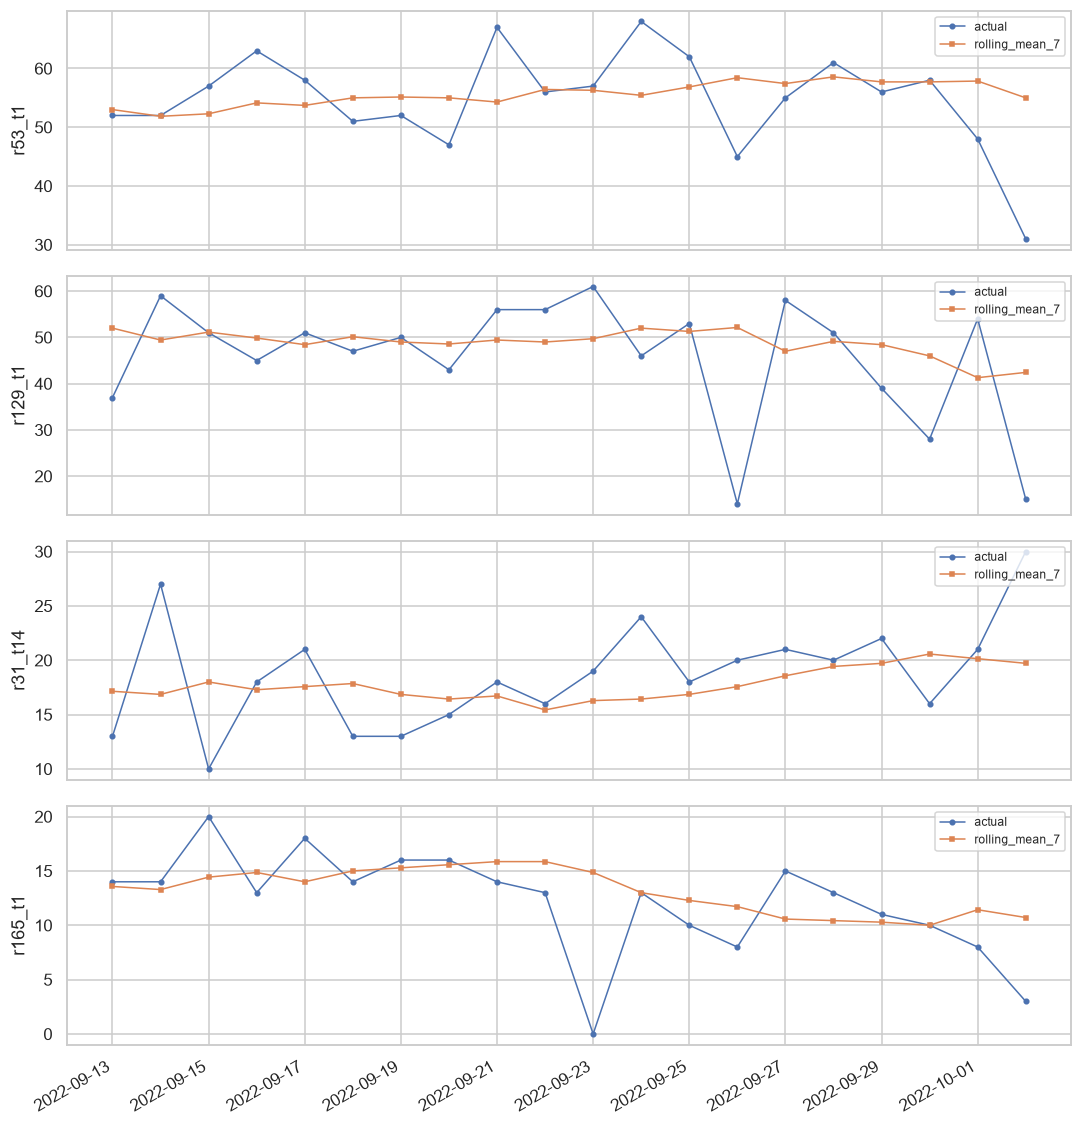

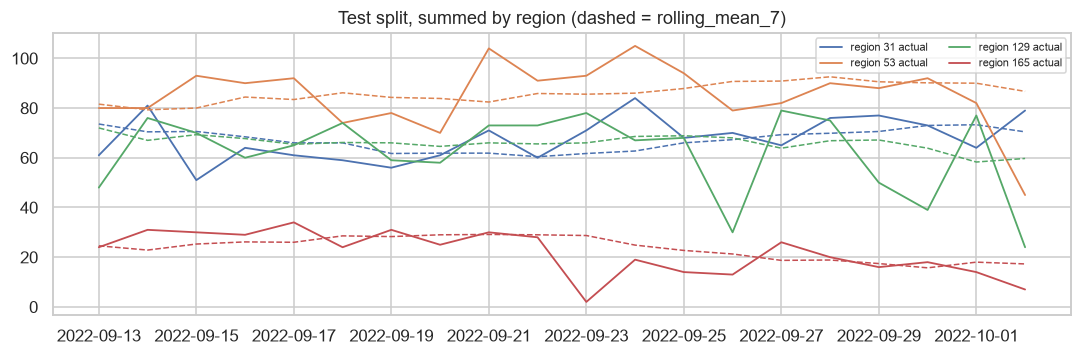

In [4]:
best = protocol["primary_stable_period"]["selected_on_validation"]
plotActualVsPredicted(predictions[predictions.scenario == "primary_stable_period"], ["r53_t1", "r129_t1", "r31_t14", "r165_t1"], best)
saveFigure("baseline_actual_vs_predicted")
region = predictions[(predictions.scenario == "primary_stable_period") & (predictions.model == best) & (predictions.split == "test")]
byRegion = region.groupby(["region_id", dateCol])[["demand", "prediction"]].sum().reset_index()
fig, ax = plt.subplots(figsize=(10, 3.4))
for r, g in byRegion.groupby("region_id"):
    ax.plot(g[dateCol], g["demand"], lw=1.2, label=f"region {r} actual")
    ax.plot(g[dateCol], g["prediction"], lw=1, ls="--", color=ax.lines[-1].get_color())
ax.set_title(f"Test split, summed by region (dashed = {best})"); ax.legend(fontsize=7, ncol=2)
saveFigure("baseline_region_level")

## 3. Sai số theo nhóm chuỗi nhu cầu cao, trung bình và thấp

In [5]:
# Groups are formed from training demand only (tertiles of the mean daily demand per series).
data = pd.read_parquet(config.featuresFile("primary_stable_period"))
trainMean = data[(data.split == "train") & data.city_observed].groupby("series_id").demand.mean()
group = pd.qcut(trainMean.rank(method="first"), 3, labels=["low", "medium", "high"])
sub = predictions[(predictions.scenario == "primary_stable_period") & (predictions.model == best) & (predictions.split == "test")].copy()
sub["demandGroup"] = sub.series_id.map(group)
rows = []
for g, s in sub.groupby("demandGroup", observed=True):
    err = (s.prediction - s.demand)
    rows.append({"group": g, "series": s.series_id.nunique(), "mean train demand": round(trainMean[s.series_id.unique()].mean(), 2),
                 "n_orders": int(s.demand.sum()), "MAE": round(err.abs().mean(), 4), "WAPE": round(err.abs().sum() / s.demand.sum(), 4)})
groupTable = pd.DataFrame(rows).set_index("group").loc[["high", "medium", "low"]]
display(groupTable[["series", "mean train demand", "n_orders", "MAE", "WAPE"]])
# Per-series and pooled metrics: pooled WAPE uses sums across all cells.
seriesRows = []
for seriesId, frame in sub.groupby("series_id"):
    score = evaluate_forecast.scoreForecast(frame.demand, frame.prediction)
    seriesRows.append({"series_id": seriesId, "n_orders": int(score["actual_orders"]), "MAE": score["mae"], "WAPE": score["wape"]})
pooled = evaluate_forecast.scoreForecast(sub.demand, sub.prediction)
seriesRows.append({"series_id": "ALL_41_POOLED", "n_orders": int(pooled["actual_orders"]), "MAE": pooled["mae"], "WAPE": pooled["wape"]})
seriesTable = pd.DataFrame(seriesRows)
display(seriesTable)
seriesTable.to_csv(config.FORECASTS_DIR / "baseline_by_series.csv", index=False)

,series,mean train demand,n_orders,MAE,WAPE
group,,,,,
high,14,16.57,4609,3.2474,0.1973
medium,13,0.44,107,0.5181,1.2590
low,14,0.06,16,0.1122,1.9643


,series_id,n_orders,MAE,WAPE
0,r129_t0,8,0.550000,1.375000
1,r129_t1,914,9.650000,0.211160
2,r129_t10,4,0.321429,1.607143
3,r129_t12,2,0.207143,2.071429
4,r129_t13,0,0.021429,NaN
5,r129_t14,262,3.792857,0.289531
6,r129_t3,8,0.550000,1.375000
7,r129_t4,9,0.600000,1.333333
8,r129_t7,36,1.242857,0.690476
9,r129_t9,0,0.000000,NaN


## 4. Kịch bản độ nhạy toàn kỳ

In [6]:
sens = metrics[(metrics.scenario == "sensitivity_full_period") & (metrics.split == "test") & (metrics.level == "series")]
display(sens[["model", "mae", "rmse", "wape", "rows", "actual_orders"]].sort_values("wape").round(4).set_index("model"))
p = protocol["sensitivity_full_period"]
print(f"scored test days: {p['scored_days']['test']} of {(pd.Timestamp(p['splits']['test'][1]) - pd.Timestamp(p['splits']['test'][0])).days + 1} calendar days in the test split")
print(f"scored test cells: {int(sens.rows.iloc[0])} (primary window: {int(primary[(primary.split == 'test') & (primary.level == 'series')].rows.iloc[0])})")

,mae,rmse,wape,rows,actual_orders
model,,,,,
naive_1,1.5279,4.6679,0.4158,574,2109.0
rolling_mean_7,2.0256,5.8292,0.5513,574,2109.0
rolling_mean_14,2.4680,7.2401,0.6717,574,2109.0
historical_mean,2.6745,7.1698,0.7279,574,2109.0
historical_weekday,2.7155,7.2676,0.7391,574,2109.0
seasonal_7,3.0662,8.7740,0.8345,574,2109.0


scored test days: 14 of 34 calendar days in the test split
scored test cells: 574 (primary window: 820)


## 5. Kết luận

## Kết luận

**Mô hình tốt nhất trong các baseline.** Trên tập kiểm tra (13/9–2/10, 820 ô, 4.732 đơn), `rolling_mean_7` có sai số nhỏ nhất ở mọi chỉ số: MAE 1,31, RMSE 3,21, WAPE 22,7% ở cấp chuỗi `region_id × aoi_type`. Thứ tự tiếp theo là `rolling_mean_14` (WAPE 23,9%), `historical_weekday` (24,9%), `historical_mean` (25,2%), `naive_1` (28,3%) và `seasonal_7` (30,6%). Trên tập kiểm định, `rolling_mean_7` cũng được chọn (WAPE 21,2%); thứ hạng đầy đủ validation được báo cáo riêng.

**Cấp vùng.** Khi cộng dự báo theo `region_id`, WAPE của `rolling_mean_7` giảm còn 14,9% (MAE 8,84 đơn/vùng/ngày), vì sai số của các chuỗi nhỏ triệt tiêu một phần khi cộng.

**Theo mức nhu cầu.** 14 chuỗi nhu cầu cao (trung bình 16,6 đơn/ngày) chiếm 4.609 trong 4.732 đơn kiểm tra và có WAPE 19,7%. Các chuỗi trung bình và thấp chỉ có 123 đơn. WAPE 126% và 196% cho thấy sai số lớn so với tổng nhu cầu của chuỗi; chỉ số này nhạy khi tổng đơn nhỏ. Vì vậy mọi bảng WAPE theo chuỗi được báo cáo kèm MAE và tổng số đơn. Chất lượng dự báo tổng thể do nhóm chuỗi nhu cầu cao quyết định.

**Lag theo tuần.** `seasonal_7` kém hơn `naive_1` và các baseline dùng trung bình, phù hợp với tương quan lag 7 gần bằng 0 ở `02_features`; Tương quan ở lag 7 yếu trong EDA; điều này chưa đủ để kết luận nhóm đặc trưng thứ trong tuần không hữu ích. Đặc trưng này được giữ làm ứng viên và đánh giá bằng mô hình và ablation ở RQ2.

**Kịch bản toàn kỳ.** Khi cửa sổ gồm cả tháng 10, chỉ 14 trong 34 ngày kiểm tra chấm được (574 ô, 2.109 đơn), vì các ngày từ 9/10 thiếu quan sát hoặc thiếu 14 ngày lịch sử. Trên các ngày này `naive_1` tốt nhất (MAE 1,53, WAPE 41,6%) còn `rolling_mean_7` có WAPE 55,1%. Khi mức nhu cầu thay đổi đột ngột, baseline chỉ dùng ngày gần nhất thích nghi nhanh hơn baseline trung bình trượt; WAPE của mọi mô hình đều cao hơn nhiều so với cửa sổ ổn định. Kết quả này là độ nhạy, không dùng để chọn mô hình.

**Mức chuẩn cho bước tiếp theo.** Mô hình học máy chỉ được coi là cải thiện khi vượt `rolling_mean_7` (MAE 1,31; WAPE 22,7% trên tập kiểm tra của cửa sổ chính) trên cùng 820 ô. Tối ưu tuyến CVRP chưa được triển khai trong phiên bản hiện tại của repo.